# 3 · Bulk flux estimates

Without turbulence measurements, the flux is estimated from mean quantities:

$$H_\mathrm{S} = \rho\, c_p\, C_\mathrm{h}\, U\, (\theta_\mathrm{s} - \theta_\mathrm{air})$$

the wind speed $U$ times the surface–air temperature difference, scaled by the **transfer coefficient**
$C_\mathrm{h}$, which describes the efficiency of turbulent mixing. $C_\mathrm{h}$ depends on

* the **roughness** of the surface: $z_{0,m}$ for momentum and $z_{0,T} = \alpha_T\, z_{0,m}$ for heat;
* the **stability**, expressed by the bulk Richardson number $Ri_\mathrm{b}$: stable stratification
  ($Ri_\mathrm{b} > 0$, surface colder than the air) suppresses turbulence, unstable stratification enhances it.

This chapter computes $H_\mathrm{S,obs,bulk}$ for one segment and shows the dependence of $C_\mathrm{h}$ on stability
and on $\alpha_T$.

> [!NOTE]
> **Paper:** Sect. 3.2, Eq. (2), Appendix B, Table B1. **Code:** `fluxpy/bulk.py` (steps B1–B3),
> `fluxpy/stability.py` (Eq. B3), `fluxpy/stability_lib.py` (the eight stability schemes), `fluxpy/util.py`
> (constants, potential temperature, pressures).

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
REPO = Path("..").resolve(); sys.path.insert(0, str(REPO))
plt.rcParams.update({"figure.dpi": 110, "figure.constrained_layout.use": True, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

AR  = REPO / "data/observations/ar"
FIG = xr.open_dataset(REPO / "data/model_output/sensitivity_figure_data.nc")      # all flux estimates on the segments
SEG = xr.open_dataset(AR / "analysis_ready_polar6_turbulent_fluxes_latest_5km.nc").sel(start_time=FIG.start_time.values)
EC  = FIG["H_obs_ec"].values

from fluxpy.util import potential_temperature, air_density, CP, G
from fluxpy.stability import bulk_richardson_2pt, Cd_Ch_noniterative
from fluxpy.bulk import reference_config
cfg = reference_config()
i = int(np.nanargmax(EC)); s = SEG.isel(start_time=i)
print("reference configuration:", cfg.scheme_name, "| alpha_T =", cfg.zt_ratio, "| z0 (open/thin/thick) =", cfg.z0_ocean, cfg.z0_thin_ice, cfg.z0_thick_ice, "m")

reference configuration: GLGS20 | alpha_T = 0.1 | z0 (open/thin/thick) = 0.0002 0.0001 0.0004 m


## Temperature difference and wind speed

The surface temperature is taken from the KT-19 infrared pyrometer, air temperature and wind from the T-Bird, all
averaged over the 5 km segment. Both temperatures are converted to potential temperature with the pressure at their
own height. Pressure is measured at the T-Bird, about 23 m above the ice, not at the surface; the surface pressure
follows from the hypsometric equation,

$$p_\mathrm{s} = p_z \exp\!\left(\frac{g\,z}{R_d\,\bar T}\right),$$

about 3 hPa above the T-Bird value. Using $p_z$ at the surface would make $\theta_\mathrm{s}$ too warm by
$g z / c_p \approx 0.23$ K, which is not negligible against typical temperature differences of one to two kelvin. The
reanalysis-driven estimates apply the same rule: the ERA5 surface pressure for $\theta_\mathrm{s}$, and the pressure of
model level 136 (about 31 m; `fluxpy.util.era5_level_pressure`) for the air temperature of that level.

In [2]:
from fluxpy.util import surface_pressure_hypsometric
T_s, T_a, p, z = float(s.t_kt19), float(s.T_mean), float(s.p_mean), float(s.altitude)
u, v = float(s.u_mean), float(s.v_mean); U = np.hypot(u, v)
p_s = float(surface_pressure_hypsometric(p, z, T_mean=0.5 * (T_s + T_a)))
th_s, th_a = float(potential_temperature(T_s, p_s)), float(potential_temperature(T_a, p))
print(f"pressure {p:.1f} hPa at the T-Bird ({z:.0f} m)  ->  {p_s:.1f} hPa at the surface")
print(f"surface {T_s:.1f} degC, air {T_a:.1f} degC  ->  theta_s - theta_air = {th_s - th_a:+.2f} K "
      f"(with the T-Bird pressure at the surface it would be {float(potential_temperature(T_s, p)) - th_a:+.2f} K);  wind {U:.1f} m/s")

pressure 1020.4 hPa at the T-Bird (25 m)  ->  1023.9 hPa at the surface
surface -15.6 degC, air -19.6 degC  ->  theta_s - theta_air = +3.70 K (with the T-Bird pressure at the surface it would be +3.95 K);  wind 2.0 m/s


## Bulk Richardson number

$$Ri_\mathrm{b} = \frac{g}{\bar\theta}\,\frac{\Delta\theta\,\Delta z}{\Delta u^2 + \Delta v^2}$$

between the surface (zero wind) and the measurement height; negative values indicate unstable stratification.

In [3]:
Ri = float(bulk_richardson_2pt(dtheta=th_a - th_s, dz=z, du=u, dv=v, theta_ref=0.5 * (th_s + th_a), eps_wind2=cfg.ri_eps_wind2))
print(f"Ri_b = {Ri:+.2f}  ->", "unstable (surface warmer than air)" if Ri < 0 else "stable")

Ri_b = -0.89  -> unstable (surface warmer than air)


## Roughness lengths

Within 5 km the surface consists of open water, thin ice and snow-covered ice. Each KT-19 sample is classified by its
temperature (above −1.8 °C: open water; at or below −20 °C: snow-covered ice; in between: thin ice). The effective
roughness length is the logarithmic average over the three fractions.

In [4]:
fr = np.array([float(s.frac_open), float(s.frac_thin_ice), float(s.frac_thick_ice)])
z0 = float(np.exp(fr @ np.log([cfg.z0_ocean, cfg.z0_thin_ice, cfg.z0_thick_ice]))); zT = cfg.zt_ratio * z0
print(f"fractions open / thin / snow-covered: {fr.round(2)}  ->  z0m = {z0:.1e} m,  z0T = alpha_T * z0m = {zT:.1e} m")

fractions open / thin / snow-covered: [0. 1. 0.]  ->  z0m = 1.0e-04 m,  z0T = alpha_T * z0m = 1.0e-05 m


## Transfer coefficient and flux

In [5]:
Cd, Ch = Cd_Ch_noniterative(Ri, z, z0, zT, cfg.scheme_name)
_, Ch_neutral = Cd_Ch_noniterative(0.0, z, z0, zT, cfg.scheme_name)
rho = float(air_density(T_a, p))
H = rho * CP * Ch * U * (th_s - th_a)
print(f"C_h = {Ch:.2e}  (neutral value {Ch_neutral:.2e}: stability changes it by a factor {Ch / Ch_neutral:.2f})")
print(f"H bulk by hand      : {H:6.1f} W m-2")
print(f"H bulk from pipeline: {float(FIG.H_obs_bulk[i]):6.1f} W m-2")
print(f"H measured (EC)     : {EC[i]:6.1f} W m-2")

C_h = 1.44e-03  (neutral value 8.89e-04: stability changes it by a factor 1.61)
H bulk by hand      :   15.0 W m-2
H bulk from pipeline:   15.0 W m-2
H measured (EC)     :   11.7 W m-2


## Dependence of $C_\mathrm{h}$ on stability

The stability dependence follows from Monin–Obukhov similarity theory, for which several formulations exist. The paper
uses Gryanik et al. (2020, GLGS20) as reference and tests seven alternatives. The shading marks the range of
$Ri_\mathrm{b}$ sampled during the campaign (central 90 % of the segments). All schemes share the unstable branch; on
the stable branch they differ, but there $C_\mathrm{h}$ and the flux are small in every scheme. The effect on the
comparison is quantified in Chapter 5.

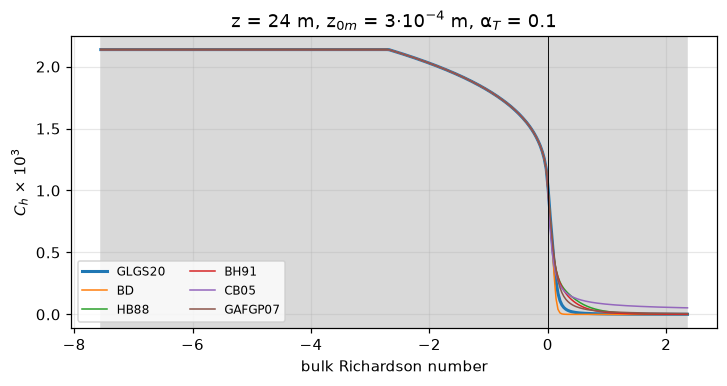

In [6]:
lo, hi = np.nanpercentile(FIG.Ri_obs.values, [5, 95])                 # central 90 % of the sampled Ri_b
ri = np.linspace(min(-1.0, lo), max(0.5, hi), 300)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for name in ["GLGS20", "BD", "HB88", "BH91", "CB05", "GAFGP07"]:
    ax.plot(ri, [Cd_Ch_noniterative(r, 24.0, 3e-4, 3e-5, name)[1] * 1e3 for r in ri], label=name, lw=2 if name == "GLGS20" else 1)
ax.axvspan(lo, hi, color="0.85")
ax.axvline(0, color="k", lw=0.6); ax.set_xlabel("bulk Richardson number"); ax.set_ylabel("$C_h$ × 10$^3$"); ax.legend(ncol=2, fontsize=8)
ax.set_title("z = 24 m, z$_{0m}$ = 3·10$^{-4}$ m, α$_T$ = 0.1");

**Figure 3.1.** Transfer coefficient $C_\mathrm{h}$ as a function of the bulk Richardson number for six of the eight
stability schemes, at the height and roughness given in the title. The grey band is the range of $Ri_\mathrm{b}$ sampled
during the campaign.

## Dependence of $C_\mathrm{h}$ on $\alpha_T$

The scalar roughness ratio $\alpha_T = z_{0,T}/z_{0,m}$ is poorly constrained over sea ice: models use values between 1
(ERA5) and 0.1 (large-eddy simulations; the reference of the paper), whereas theory and earlier aircraft measurements
indicate much smaller values. $C_\mathrm{h}$ depends on it logarithmically:

alpha_T from 1e-1 to 1e-4 (three orders of magnitude) changes C_h by a factor 0.66


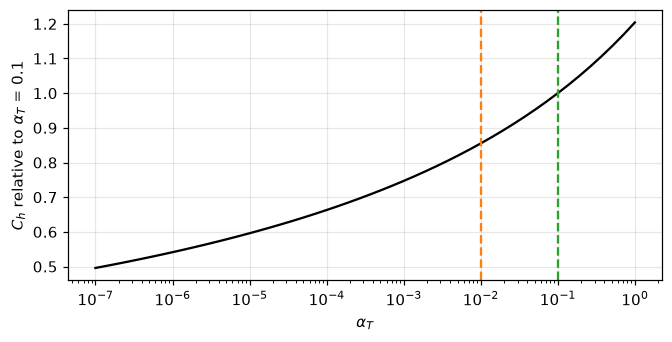

In [7]:
a = np.logspace(-7, 0, 50)
ch = np.array([Cd_Ch_noniterative(0.0, 24.0, 3e-4, 3e-4 * x, "GLGS20")[1] for x in a])
fig, ax = plt.subplots(figsize=(6, 3)); ax.semilogx(a, ch / ch[np.argmin(abs(a - 0.1))], color="k")
ax.axvline(0.1, color="C2", ls="--"); ax.axvline(1e-2, color="C1", ls="--")
ax.set_xlabel(r"$\alpha_T$"); ax.set_ylabel(r"$C_h$ relative to $\alpha_T$ = 0.1")
print(f"alpha_T from 1e-1 to 1e-4 (three orders of magnitude) changes C_h by a factor {ch[np.argmin(abs(a - 1e-4))] / ch[np.argmin(abs(a - 0.1))]:.2f}")

**Figure 3.2.** $C_\mathrm{h}$ under neutral stratification as a function of $\alpha_T$, relative to its value at
$\alpha_T = 0.1$. Dashed lines: reference configuration ($\alpha_T = 0.1$, green) and amplitude-matched configuration
($\alpha_T = 10^{-2}$, orange).

**Summary.** The bulk flux is the product of wind speed, temperature difference and $C_\mathrm{h}$, which contains
roughness and stability. Roughness scales the flux and thus changes its *amplitude*, but not *where* along the track the
flux is large or small; that is determined by the temperature difference and the wind. This distinction structures the
results of Chapters 4 and 5.